In [1]:
######################################################################################
# Authored by Andrew Wan Ju Kang, Ph.D.
# soarhigh0714@gmail.com
# Do not re-distribute.
######################################################################################

# GGUF 4-bit 양자화 모델 + LangChain v1.0 Agent

이미 변환된 GGUF 4-bit 양자화 모델을 `llama-server`로 로드한 뒤,  
**LangChain v1.0**의 `create_agent`를 사용하여 ReAct 에이전트를 구성합니다.

### 이미지 인식 실습
* 로컬 이미지를 인식하여 성능이 얼마나 나오는지 비교합니다.

## 1. LangChain v1.0 `create_agent`로 에이전트 구성

### ✅ 핵심 포인트

| 항목 | 설명 |
|---|---|
| **import** | `from langchain.agents import create_agent` |
| **에이전트 생성** | `create_agent(model=llm, tools=tools, system_prompt=...)` |
| **필요 패키지** | `langchain>=1.0`, `langchain-openai` |
| **LangGraph** | 내부적으로 사용되지만 직접 import 불필요 |

> `create_agent`는 내부적으로 LangGraph 런타임 위에서 동작하지만,
> 사용자가 LangGraph API를 직접 다룰 필요는 없습니다.
>
> 로컬 llama-server는 OpenAI 호환 API를 제공하므로,
> `ChatOpenAI`에 `base_url`을 지정하여 연결합니다.


In [2]:
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

# ─── 서버 설정 ───
SERVER_HOST = "127.0.0.1"
SERVER_PORT = 8181

# ─── LLM 연결: llama-server → OpenAI 호환 API ───
llm = ChatOpenAI(
    model="gemma",                                       # 모델명 (llama-server에서는 무시됨)
    base_url=f"http://{SERVER_HOST}:{SERVER_PORT}/v1",          # 로컬 llama-server
    api_key="not-needed",                                       # 로컬 서버이므로 불필요
    temperature=0.1,
    max_tokens=4096,
)

# ─── 시스템 프롬프트 ───
SYSTEM_PROMPT = """You are a helpful AI assistant with access to tools."""

agent = create_agent(
    model=llm,
    tools=[],
    system_prompt=SYSTEM_PROMPT,
)

print("✅ LangChain v1.0 ReAct 에이전트 생성 완료!")

/opt/conda/lib/python3.10/site-packages/langgraph/checkpoint/serde/encrypted.py:5: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


✅ LangChain v1.0 ReAct 에이전트 생성 완료!


## 2. 에이전트 실행 함수

두 가지 실행 방식을 제공합니다:

| 방식 | 함수 | 설명 |
|---|---|---|
| **invoke** | `run_agent()` | 전체 결과를 한 번에 받음 |
| **stream** | `run_agent_stream()` | 단계별 스트리밍 |

참조: [Agents - Invocation](https://docs.langchain.com/oss/python/langchain/agents)

In [3]:
# base64 인코딩 처리를 위해 base64 모듈을 불러옵니다.
import base64

# 파일의 MIME 타입을 추론하기 위해 mimetypes 모듈을 불러옵니다.
import mimetypes


# 일반 invoke 방식으로 에이전트를 실행하는 함수를 정의합니다.
def run_agent(query: str, image_url: str = None, verbose: bool = True):
    # 함수의 역할과 인자 설명을 위한 문서 문자열입니다.
    """에이전트를 invoke 방식으로 실행합니다.

    Args:
        query: 질문 텍스트
        image_url: 이미지 URL 또는 로컬 파일 경로 (선택, 멀티모달)
        verbose: 중간 단계 출력 여부
    """
    # 구분선을 출력해 실행 시작을 보기 쉽게 만듭니다.
    print(f"\n{'='*60}")
    # 사용자가 입력한 질문을 출력합니다.
    print(f"📝 질문: {query}")
    # 이미지가 함께 들어온 경우 이미지 경로 또는 URL도 출력합니다.
    if image_url:
        print(f"🖼️ 이미지: {image_url}")
    # 다시 구분선을 출력합니다.
    print(f"{'='*60}")

    # ─── 메시지 구성 ───
    # 이미지가 포함된 멀티모달 입력인지 확인합니다.
    if image_url:
        # 이미지 경로가 http로 시작하지 않으면 로컬 파일로 간주합니다.
        if not image_url.startswith("http"):
            # 파일 확장자를 기반으로 MIME 타입을 추론하고, 실패하면 기본값으로 image/png를 사용합니다.
            mime = mimetypes.guess_type(image_url)[0] or "image/png"
            # 로컬 이미지 파일을 바이너리 읽기 모드로 엽니다.
            with open(image_url, "rb") as f:
                # 파일 내용을 base64 문자열로 인코딩합니다.
                b64 = base64.b64encode(f.read()).decode()
            # base64 데이터 URL 형식으로 변환하여 모델에 전달할 수 있게 만듭니다.
            url = f"data:{mime};base64,{b64}"
        else:
            # 이미 URL 형태라면 그대로 사용합니다.
            url = image_url

        # 멀티모달 입력용 user 메시지를 이미지와 텍스트를 함께 포함하는 형식으로 구성합니다.
        user_message = {
            "role": "user",
            "content": [
                {"type": "image_url", "image_url": {"url": url}},
                {"type": "text", "text": query},
            ],
        }
    else:
        # 이미지가 없는 경우 일반 텍스트 메시지 형식으로 구성합니다.
        user_message = {"role": "user", "content": query}

    # ─── 에이전트 실행 (invoke) ───
    # 구성한 메시지를 에이전트에 전달하여 한 번에 실행합니다.
    result = agent.invoke({"messages": [user_message]})

    # ─── 결과 출력 ───
    # verbose가 True이면 중간 단계 정보까지 출력합니다.
    if verbose:
        # 에이전트가 생성한 전체 메시지를 순회합니다.
        for msg in result["messages"]:
            # 현재 메시지에 tool_calls 속성이 있고 실제 툴 호출이 존재하는지 확인합니다.
            if hasattr(msg, "tool_calls") and msg.tool_calls:
                # 각 툴 호출 정보를 하나씩 출력합니다.
                for tc in msg.tool_calls:
                    print(f"  🔧 Tool Call: {tc['name']}({tc['args']})")
            # 현재 메시지가 tool 실행 결과 메시지인지 확인합니다.
            elif hasattr(msg, "type") and msg.type == "tool":
                # 툴 이름과 실행 결과를 출력합니다.
                print(f"  📦 Tool Result [{msg.name}]: {msg.content}")

    # 마지막 메시지의 content를 최종 응답으로 추출합니다.
    final_response = result["messages"][-1].content
    # 최종 응답을 화면에 출력합니다.
    print(f"\n🎯 최종 응답:\n{final_response}")
    # 최종 응답 문자열을 반환합니다.
    return final_response


# stream 방식으로 에이전트를 실행하는 함수를 정의합니다.
def run_agent_stream(query: str, image_url: str = None, verbose: bool = True):
    # 함수의 역할과 인자 설명을 위한 문서 문자열입니다.
    """에이전트를 stream 방식으로 실행합니다.

    Args:
        query: 질문 텍스트
        image_url: 이미지 URL 또는 로컬 파일 경로 (선택, 멀티모달)
        verbose: 중간 단계 출력 여부
    """
    # 구분선을 출력해 스트리밍 실행 시작을 보기 쉽게 만듭니다.
    print(f"\n{'='*60}")
    # 스트리밍 방식 질문임을 표시하며 질문을 출력합니다.
    print(f"📝 질문 (스트리밍): {query}")
    # 이미지가 함께 들어온 경우 이미지 경로 또는 URL도 출력합니다.
    if image_url:
        print(f"🖼️ 이미지: {image_url}")
    # 다시 구분선을 출력합니다.
    print(f"{'='*60}")

    # ─── 메시지 구성 ───
    # 이미지가 포함된 멀티모달 입력인지 확인합니다.
    if image_url:
        # 이미지 경로가 http로 시작하지 않으면 로컬 파일로 간주합니다.
        if not image_url.startswith("http"):
            # 파일 확장자를 기반으로 MIME 타입을 추론하고, 실패하면 기본값으로 image/png를 사용합니다.
            mime = mimetypes.guess_type(image_url)[0] or "image/png"
            # 로컬 이미지 파일을 바이너리 읽기 모드로 엽니다.
            with open(image_url, "rb") as f:
                # 파일 내용을 base64 문자열로 인코딩합니다.
                b64 = base64.b64encode(f.read()).decode()
            # base64 데이터 URL 형식으로 변환하여 모델에 전달할 수 있게 만듭니다.
            url = f"data:{mime};base64,{b64}"
        else:
            # 이미 URL 형태라면 그대로 사용합니다.
            url = image_url

        # 멀티모달 입력용 user 메시지를 이미지와 텍스트를 함께 포함하는 형식으로 구성합니다.
        user_message = {
            "role": "user",
            "content": [
                {"type": "image_url", "image_url": {"url": url}},
                {"type": "text", "text": query},
            ],
        }
    else:
        # 이미지가 없는 경우 일반 텍스트 메시지 형식으로 구성합니다.
        user_message = {"role": "user", "content": query}

    # ─── 에이전트 스트리밍 실행 ───
    # 마지막 스트리밍 결과를 저장할 변수를 초기화합니다.
    step = None

    # 에이전트를 stream 모드로 실행하면서 각 중간 단계를 순회합니다.
    for step in agent.stream(
        {"messages": [user_message]},
        stream_mode="values",
    ):
        # 현재 단계의 마지막 메시지를 가져옵니다.
        last_msg = step["messages"][-1]

        # 마지막 메시지에 tool_calls가 있으면 툴 호출 정보를 출력합니다.
        if hasattr(last_msg, "tool_calls") and last_msg.tool_calls:
            # 여러 개의 툴 호출이 있을 수 있으므로 하나씩 순회합니다.
            for tc in last_msg.tool_calls:
                # verbose가 True일 때만 툴 호출 로그를 출력합니다.
                if verbose:
                    print(f"  🔧 Tool Call: {tc['name']}({tc['args']})")
        # 마지막 메시지가 tool 결과 메시지이면 실행 결과를 출력합니다.
        elif hasattr(last_msg, "type") and last_msg.type == "tool":
            # verbose가 True일 때만 툴 결과 로그를 출력합니다.
            if verbose:
                print(f"  📦 Tool Result [{last_msg.name}]: {last_msg.content}")

    # 스트리밍 결과가 하나라도 있었다면 마지막 단계에서 최종 응답을 추출합니다.
    if step:
        # 마지막 단계의 마지막 메시지 content를 최종 응답으로 저장합니다.
        final_response = step["messages"][-1].content
        # 최종 응답을 출력합니다.
        print(f"\n🎯 최종 응답:\n{final_response}")
        # 최종 응답 문자열을 반환합니다.
        return final_response

    # 스트리밍 결과가 전혀 없었다면 None을 반환합니다.
    return None


# 실행 함수 정의가 완료되었음을 출력합니다.
print("✅ 실행 함수 정의 완료!")

✅ 실행 함수 정의 완료!


## 3. 실행 예시

### 이미지 + 텍스트 (멀티모달)

✅ 테스트 이미지 확인: /home/user/MultiAgents/Day_3/Ex/data/test_imgs/dataframe.jpg
이미지 크기: (1280, 720)


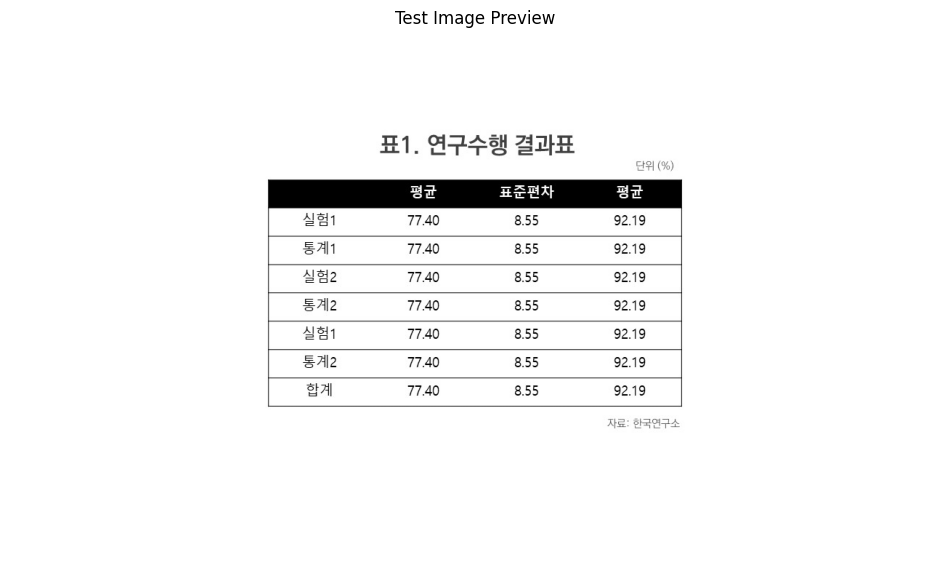

In [4]:
from PIL import Image
import matplotlib.pyplot as plt
import os

TEST_IMAGE = "/home/user/MultiAgents/Day_3/Ex/data/test_imgs/dataframe.jpg"

assert os.path.exists(TEST_IMAGE), f"이미지 파일이 없습니다: {TEST_IMAGE}"
print("✅ 테스트 이미지 확인:", TEST_IMAGE)

img = Image.open(TEST_IMAGE).convert("RGB")
print("이미지 크기:", img.size)

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off")
plt.title("Test Image Preview")
plt.show()

In [5]:
run_agent(
    "이 이미지에 무엇이 보이는지 설명해줘",
    image_url=TEST_IMAGE,
)


📝 질문: 이 이미지에 무엇이 보이는지 설명해줘
🖼️ 이미지: /home/user/MultiAgents/Day_3/Ex/data/test_imgs/dataframe.jpg

🎯 최종 응답:
제공해주신 이미지는 **"표1. 연구 수행 결과표"**로 보이는 표입니다.

이 표는 연구 수행 결과에 대한 데이터를 정리하고 있으며, 다음과 같은 구조로 구성되어 있습니다.

### 표의 구성 요소 분석

표는 세 개의 주요 열(Column)과 여러 행(Row)으로 이루어져 있습니다.

**1. 제목:**
*   **표1. 연구 수행 결과표**

**2. 열 제목 (Column Headers):**
표의 상단에는 세 가지 항목이 있습니다.
*   **평균 (Average)**
*   **표준편차 (Standard Deviation)**
*   **평균 (Average)** (두 번째 '평균'은 아마도 다른 종류의 평균이나 최종 결과를 나타낼 수 있습니다.)
*   오른쪽 상단에는 **단위 (%)**라고 표시되어 있어, 이 데이터들이 백분율(%)로 측정되었음을 알 수 있습니다.

**3. 행 데이터 (Row Data):**
데이터는 실험(실험)과 통계(통계) 항목으로 구분되어 있으며, 각 항목별로 세 가지 수치가 나열되어 있습니다.

*   **실험 1 (Experiment 1):**
    *   평균: 77.40
    *   표준편차: 8.55
    *   평균: 92.19
*   **통계 1 (Statistics 1):**
    *   평균: 77.40
    *   표준편차: 8.55
    *   평균: 92.19
*   **실험 2 (Experiment 2):**
    *   평균: 77.40
    *   표준편차: 8.55
    *   평균: 92.19
*   **통계 2 (Statistics 2):**
    *   평균: 77.40
    *   표준편차: 8.55
    *   평균: 92.19
*   **실험 1 (Experiment 1) -

'제공해주신 이미지는 **"표1. 연구 수행 결과표"**로 보이는 표입니다.\n\n이 표는 연구 수행 결과에 대한 데이터를 정리하고 있으며, 다음과 같은 구조로 구성되어 있습니다.\n\n### 표의 구성 요소 분석\n\n표는 세 개의 주요 열(Column)과 여러 행(Row)으로 이루어져 있습니다.\n\n**1. 제목:**\n*   **표1. 연구 수행 결과표**\n\n**2. 열 제목 (Column Headers):**\n표의 상단에는 세 가지 항목이 있습니다.\n*   **평균 (Average)**\n*   **표준편차 (Standard Deviation)**\n*   **평균 (Average)** (두 번째 \'평균\'은 아마도 다른 종류의 평균이나 최종 결과를 나타낼 수 있습니다.)\n*   오른쪽 상단에는 **단위 (%)**라고 표시되어 있어, 이 데이터들이 백분율(%)로 측정되었음을 알 수 있습니다.\n\n**3. 행 데이터 (Row Data):**\n데이터는 실험(실험)과 통계(통계) 항목으로 구분되어 있으며, 각 항목별로 세 가지 수치가 나열되어 있습니다.\n\n*   **실험 1 (Experiment 1):**\n    *   평균: 77.40\n    *   표준편차: 8.55\n    *   평균: 92.19\n*   **통계 1 (Statistics 1):**\n    *   평균: 77.40\n    *   표준편차: 8.55\n    *   평균: 92.19\n*   **실험 2 (Experiment 2):**\n    *   평균: 77.40\n    *   표준편차: 8.55\n    *   평균: 92.19\n*   **통계 2 (Statistics 2):**\n    *   평균: 77.40\n    *   표준편차: 8.55\n    *   평균: 92.19\n*   **실험 1 (Experiment 1) - 반복 또는 다른 측정:**\n    *   평균: 77.40\n    *   표준편차: 8.55\n    *   평균:

In [6]:
# 프롬프트로 정형 데이터 파싱해보기
run_agent(
    "",
    image_url=TEST_IMAGE,
)


📝 질문: 
🖼️ 이미지: /home/user/MultiAgents/Day_3/Ex/data/test_imgs/dataframe.jpg

🎯 최종 응답:
This image displays a table titled "**표1. 연구수행 결과표**" (Table 1. Research Results Table).

The table presents data categorized by **실험 (Experiment)**, **통계 (Statistics)**, and **합계 (Total)**, with three columns: **평균 (Average)**, **표준편차 (Standard Deviation)**, and another **평균 (Average)** column (which seems redundant or perhaps represents a different type of average/result). The unit is indicated as **단위 (%)** (Unit (%)).

Here is a transcription and breakdown of the data:

| Category | 평균 (Average) | 표준편차 (Standard Deviation) | 평균 (Average) |
| :--- | :--- | :--- | :--- |
| 실험1 (Experiment 1) | 77.40 | 8.55 | 92.19 |
| 통계1 (Statistics 1) | 77.40 | 8.55 | 92.19 |
| 실험2 (Experiment 2) | 77.40 | 8.55 | 92.19 |
| 통계2 (Statistics 2) | 77.40 | 8.55 | 92.19 |
| 실험1 (Experiment 1) | 77.40 | 8.55 | 92.19 |
| 통계2 (Statistics 2) | 77.40 | 8.55 | 92.19 |
| 합계 (Total) | 77.40 | 8.55 | 92.19 |

**Source:** 자료: 한국

'This image displays a table titled "**표1. 연구수행 결과표**" (Table 1. Research Results Table).\n\nThe table presents data categorized by **실험 (Experiment)**, **통계 (Statistics)**, and **합계 (Total)**, with three columns: **평균 (Average)**, **표준편차 (Standard Deviation)**, and another **평균 (Average)** column (which seems redundant or perhaps represents a different type of average/result). The unit is indicated as **단위 (%)** (Unit (%)).\n\nHere is a transcription and breakdown of the data:\n\n| Category | 평균 (Average) | 표준편차 (Standard Deviation) | 평균 (Average) |\n| :--- | :--- | :--- | :--- |\n| 실험1 (Experiment 1) | 77.40 | 8.55 | 92.19 |\n| 통계1 (Statistics 1) | 77.40 | 8.55 | 92.19 |\n| 실험2 (Experiment 2) | 77.40 | 8.55 | 92.19 |\n| 통계2 (Statistics 2) | 77.40 | 8.55 | 92.19 |\n| 실험1 (Experiment 1) | 77.40 | 8.55 | 92.19 |\n| 통계2 (Statistics 2) | 77.40 | 8.55 | 92.19 |\n| 합계 (Total) | 77.40 | 8.55 | 92.19 |\n\n**Source:** 자료: 한국연구소 (Source: Korea Research Institute)\n\n**In summary, the table show

✅ 테스트 이미지 확인: /home/user/MultiAgents/Day_3/Ex/data/test_imgs/sign.png
이미지 크기: (1122, 750)


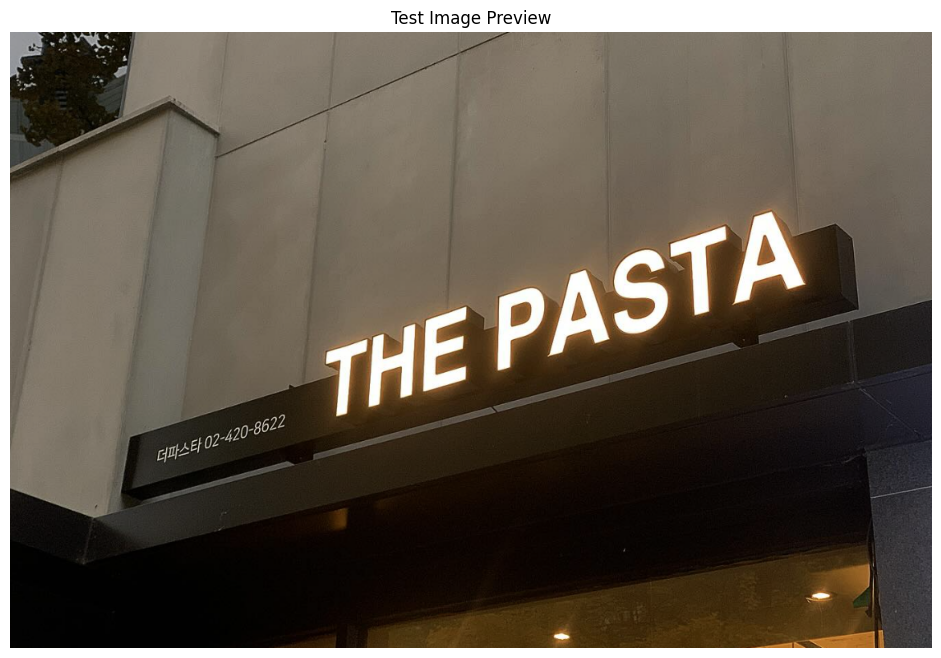

In [7]:
TEST_IMAGE = "/home/user/MultiAgents/Day_3/Ex/data/test_imgs/sign.png"

assert os.path.exists(TEST_IMAGE), f"이미지 파일이 없습니다: {TEST_IMAGE}"
print("✅ 테스트 이미지 확인:", TEST_IMAGE)

img = Image.open(TEST_IMAGE).convert("RGB")
print("이미지 크기:", img.size)

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off")
plt.title("Test Image Preview")
plt.show()

In [8]:
run_agent(
    "이 이미지에 무엇이 보이는지 설명해줘",
    image_url=TEST_IMAGE,
)


📝 질문: 이 이미지에 무엇이 보이는지 설명해줘
🖼️ 이미지: /home/user/MultiAgents/Day_3/Ex/data/test_imgs/sign.png

🎯 최종 응답:
제공해주신 이미지에는 **'THE PASTA'**라는 간판이 보입니다.

**이미지에서 확인할 수 있는 주요 내용은 다음과 같습니다:**

1. **간판:** 건물 외벽에 크고 밝은 **흰색(또는 밝은 노란색)** 글씨로 **"THE PASTA"**라고 쓰여 있습니다. 이 간판은 어두운 배경(건물 외벽)과 대비되어 잘 눈에 띕니다.
2. **건물 외벽:** 간판 뒤쪽으로는 밝은 베이지색 또는 연한 갈색 계열의 현대적인 건물 외벽이 보입니다.
3. **추가 텍스트 (한글/일본어):** 간판 아래쪽(왼쪽)에 작은 글씨로 한글 또는 일본어로 보이는 텍스트가 있습니다. (예: "테파스타 02-420-8622"와 유사한 형태)
4. **상점 입구:** 간판 아래쪽으로는 어두운 색(검은색 계열)의 상점 입구 또는 유리창 부분이 보입니다.

**요약하자면, 이 이미지는 'THE PASTA'라는 식당이나 레스토랑의 외부 간판과 그 주변 건물 일부를 포착한 사진입니다.**


'제공해주신 이미지에는 **\'THE PASTA\'**라는 간판이 보입니다.\n\n**이미지에서 확인할 수 있는 주요 내용은 다음과 같습니다:**\n\n1. **간판:** 건물 외벽에 크고 밝은 **흰색(또는 밝은 노란색)** 글씨로 **"THE PASTA"**라고 쓰여 있습니다. 이 간판은 어두운 배경(건물 외벽)과 대비되어 잘 눈에 띕니다.\n2. **건물 외벽:** 간판 뒤쪽으로는 밝은 베이지색 또는 연한 갈색 계열의 현대적인 건물 외벽이 보입니다.\n3. **추가 텍스트 (한글/일본어):** 간판 아래쪽(왼쪽)에 작은 글씨로 한글 또는 일본어로 보이는 텍스트가 있습니다. (예: "테파스타 02-420-8622"와 유사한 형태)\n4. **상점 입구:** 간판 아래쪽으로는 어두운 색(검은색 계열)의 상점 입구 또는 유리창 부분이 보입니다.\n\n**요약하자면, 이 이미지는 \'THE PASTA\'라는 식당이나 레스토랑의 외부 간판과 그 주변 건물 일부를 포착한 사진입니다.**'

**더 해보기**

복습자료 구글드라이브에 있는 사진 4장을 아래 경로에 놓고 다양한 OCR 질문을 입력해보세요

사진 4장:

enquete_figure.jpg

flask_figure.jpg

meta_revenue_sankey.jpg

sightation_figure.jpg

경로:

/home/user/MultiAgents/Day_3/Ex/data/test_imgs/